Libraries imported successfully.

Output directory: /kaggle/working/XGBoost_Output

Searching for the dataset in Kaggle input...

Dataset successfully detected!
Actual dataset path: /kaggle/input/datasets/sovitrath/diabetic-retinopathy-2015-data-colored-resized/colored_images/colored_images

Detected Classes:
 - Mild
 - Moderate
 - No_DR
 - Proliferate_DR
 - Severe

Original Dataset Distribution:
         Class  Number of Images
          Mild              2443
      Moderate              5292
         No_DR             25810
Proliferate_DR               708
        Severe               873


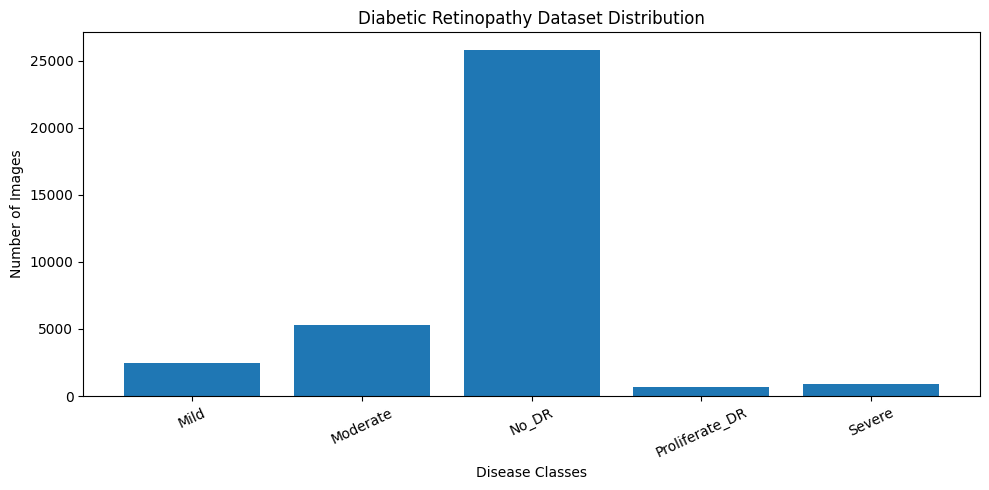


Starting feature extraction...

Processing Mild: 1000 images


  0%|          | 0/1000 [00:00<?, ?it/s]


Processing Moderate: 1000 images


  0%|          | 0/1000 [00:00<?, ?it/s]


Processing No_DR: 1000 images


  0%|          | 0/1000 [00:00<?, ?it/s]


Processing Proliferate_DR: 708 images


  0%|          | 0/708 [00:00<?, ?it/s]


Processing Severe: 873 images


  0%|          | 0/873 [00:00<?, ?it/s]


Feature extraction completed.

Feature Matrix: (4581, 8207)
Target Matrix: (4581,)
Total Processed Images: 4581

Processed Class Distribution:
Mild              1000
Moderate          1000
No_DR             1000
Proliferate_DR     708
Severe             873
Name: count, dtype: int64

Expected feature dimensions: 8206
Actual feature dimensions: 8207

Class Encoding:
Mild = 0
Moderate = 1
No_DR = 2
Proliferate_DR = 3
Severe = 4

Dataset Split:
Training: (3206, 8207)
Validation: (687, 8207)
Testing: (688, 8207)

Class balancing weights calculated.

XGBoost model initialized.
XGBoost version: 3.4.1

Starting model training...
[0]	validation_0-mlogloss:1.60172	validation_1-mlogloss:1.60614
[50]	validation_0-mlogloss:1.32689	validation_1-mlogloss:1.53568
[100]	validation_0-mlogloss:1.13907	validation_1-mlogloss:1.51946
[150]	validation_0-mlogloss:0.98884	validation_1-mlogloss:1.51040
[200]	validation_0-mlogloss:0.86446	validation_1-mlogloss:1.50331
[250]	validation_0-mlogloss:0.75992	valida

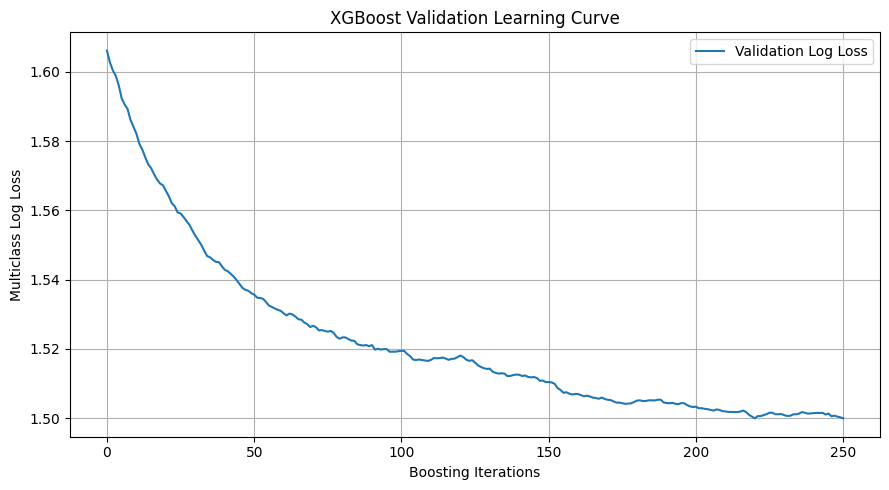


Training RESULTS
Accuracy: 0.9588
Macro Precision: 0.9570
Macro Recall: 0.9604
Macro F1: 0.9582
Weighted F1: 0.9590

Validation RESULTS
Accuracy: 0.2984
Macro Precision: 0.3001
Macro Recall: 0.3115
Macro F1: 0.3037
Weighted F1: 0.2939

Testing RESULTS
Accuracy: 0.3256
Macro Precision: 0.3258
Macro Recall: 0.3378
Macro F1: 0.3302
Weighted F1: 0.3209

Overall Evaluation Results:
   Dataset  Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1
  Training  0.958827         0.957037      0.960353  0.958210     0.958955
Validation  0.298399         0.300130      0.311482  0.303717     0.293947
   Testing  0.325581         0.325778      0.337762  0.330245     0.320908

Final Test Classification Report:

                precision    recall  f1-score   support

          Mild       0.26      0.27      0.27       150
      Moderate       0.22      0.18      0.20       150
         No_DR       0.38      0.35      0.36       150
Proliferate_DR       0.43      0.52      0.47       107
  

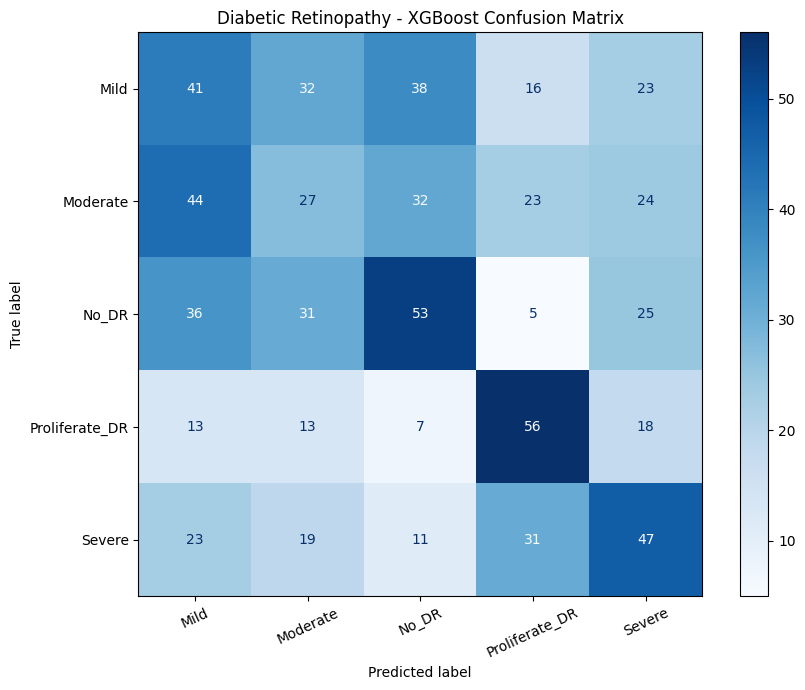

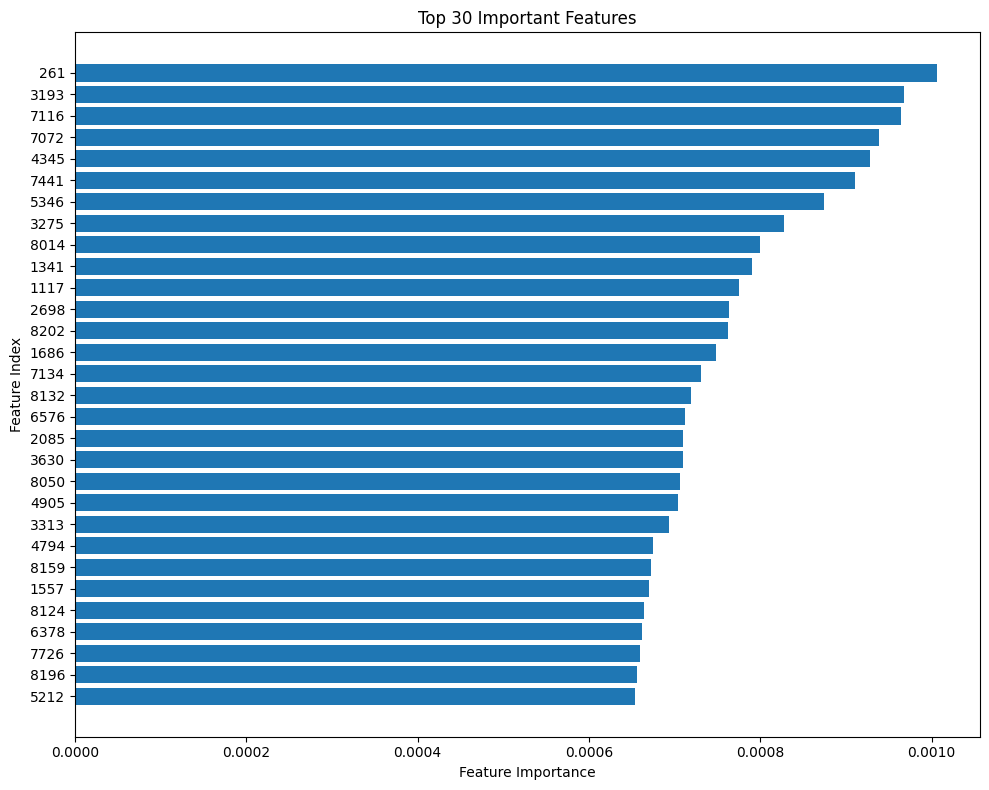


ZIP created successfully:
/kaggle/working/XGBoost_Output.zip

DIABETIC RETINOPATHY CLASSIFICATION COMPLETED
Dataset: /kaggle/input/datasets/sovitrath/diabetic-retinopathy-2015-data-colored-resized/colored_images/colored_images
Total Images: 4581
Feature Dimensions: 8207
Number of Classes: 5
Training Images: 3206
Validation Images: 687
Testing Images: 688

Final Test Accuracy: 0.3256
Final Test Macro F1: 0.3302

Output Folder: /kaggle/working/XGBoost_Output
ZIP File: /kaggle/working/XGBoost_Output.zip

Generated Files:
 - class_distribution.png
 - classification_report.txt
 - confusion_matrix.png
 - diabetic_retinopathy_xgboost.json
 - diabetic_retinopathy_xgboost.pkl
 - evaluation_results.csv
 - experiment_configuration.json
 - feature_importance.csv
 - feature_importance.png
 - label_encoder.pkl
 - learning_curve.png
 - test_predictions.csv
 - training_history.json

ALL EXPERIMENTS COMPLETED SUCCESSFULLY.


In [1]:

# ================================================================
# DIABETIC RETINOPATHY CLASSIFICATION USING XGBOOST
# HOG + RGB COLOR HISTOGRAM + LBP
# COMPLETE KAGGLE IMPLEMENTATION
# ================================================================


# ================================================================
# 1. INSTALL LIBRARIES
# ================================================================

!pip -q install -U xgboost scikit-image

import os
import gc
import cv2
import json
import shutil
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from skimage.feature import hog, local_binary_pattern

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

print("Libraries imported successfully.")


# ================================================================
# 2. CONFIGURATION
# ================================================================

OUTPUT_DIR = "/kaggle/working/XGBoost_Output"
CACHE_FILE = "/kaggle/working/dr_feature_cache.npz"
ZIP_PATH = "/kaggle/working/XGBoost_Output.zip"

IMAGE_SIZE = 128
MAX_IMAGES_PER_CLASS = 1000
RANDOM_STATE = 42

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("\nOutput directory:", OUTPUT_DIR)


# ================================================================
# 3. AUTOMATICALLY FIND DATASET DIRECTORY
# ================================================================

INPUT_DIR = "/kaggle/input"

REQUIRED_CLASSES = {
    "Mild",
    "Moderate",
    "No_DR",
    "Proliferate_DR",
    "Severe"
}

if not os.path.exists(INPUT_DIR):
    raise FileNotFoundError(
        "/kaggle/input does not exist. "
        "Run this code inside a Kaggle notebook."
    )

print("\nSearching for the dataset in Kaggle input...")


def find_dataset(root_directory):

    matches = []

    for root, dirs, files in os.walk(root_directory):

        folder_names = set(dirs)

        if REQUIRED_CLASSES.issubset(folder_names):
            matches.append(root)

    return matches


dataset_candidates = find_dataset(INPUT_DIR)

if not dataset_candidates:

    print("\nDataset folders were not detected.")

    print("\nAvailable Kaggle input directories:")

    for item in os.listdir(INPUT_DIR):

        item_path = os.path.join(INPUT_DIR, item)

        print("\n", item)

        if os.path.isdir(item_path):

            for sub_item in os.listdir(item_path)[:20]:
                print("   ", sub_item)

    raise FileNotFoundError(
        "\nCould not locate all five class folders. "
        "Open Kaggle notebook > Add Input and attach "
        "the Diabetic Retinopathy dataset."
    )


DATASET_PATH = dataset_candidates[0]

print("\nDataset successfully detected!")
print("Actual dataset path:", DATASET_PATH)


# ================================================================
# 4. VERIFY DATASET CLASSES
# ================================================================

class_names = sorted([
    folder
    for folder in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, folder))
    and folder in REQUIRED_CLASSES
])

if set(class_names) != REQUIRED_CLASSES:
    raise ValueError(
        "Dataset class folders do not match the expected five classes."
    )

print("\nDetected Classes:")

for class_name in class_names:
    print(" -", class_name)


# ================================================================
# 5. IMAGE EXTENSIONS AND DATASET DISTRIBUTION
# ================================================================

VALID_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff"
)

class_distribution = {}

for class_name in class_names:

    class_path = os.path.join(
        DATASET_PATH,
        class_name
    )

    image_files = [
        file for file in os.listdir(class_path)
        if file.lower().endswith(VALID_EXTENSIONS)
    ]

    class_distribution[class_name] = len(image_files)


distribution_df = pd.DataFrame(
    list(class_distribution.items()),
    columns=["Class", "Number of Images"]
)

print("\nOriginal Dataset Distribution:")
print(distribution_df.to_string(index=False))


plt.figure(figsize=(10, 5))

plt.bar(
    distribution_df["Class"],
    distribution_df["Number of Images"]
)

plt.title("Diabetic Retinopathy Dataset Distribution")
plt.xlabel("Disease Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=25)

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "class_distribution.png"),
    dpi=300
)

plt.show()


# ================================================================
# 6. FEATURE EXTRACTION FUNCTION
# ==============================================================

def extract_features(image_path):

    image = cv2.imread(image_path)

    if image is None:
        return None

    image = cv2.resize(
        image,
        (IMAGE_SIZE, IMAGE_SIZE)
    )

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    # HOG FEATURES

    hog_features = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True
    )

    # RGB COLOR HISTOGRAM

    color_features = []

    for channel in range(3):

        histogram = cv2.calcHist(
            [image],
            [channel],
            None,
            [32],
            [0, 256]
        ).flatten()

        histogram = histogram / (
            histogram.sum() + 1e-7
        )

        color_features.extend(histogram)

    color_features = np.array(
        color_features,
        dtype=np.float32
    )

    # LOCAL BINARY PATTERN

    lbp = local_binary_pattern(
        gray,
        P=8,
        R=1,
        method="uniform"
    )

    lbp_histogram, _ = np.histogram(
        lbp.ravel(),
        bins=np.arange(0, 12),
        range=(0, 11)
    )

    lbp_histogram = lbp_histogram.astype(
        np.float32
    )

    lbp_histogram = lbp_histogram / (
        lbp_histogram.sum() + 1e-7
    )

    # COMBINE FEATURES

    combined_features = np.concatenate([
        hog_features,
        color_features,
        lbp_histogram
    ])

    return combined_features.astype(np.float32)


# ================================================================
# 7. LOAD FEATURE CACHE OR EXTRACT FEATURES
# ================================================================

if os.path.exists(CACHE_FILE):

    print("\nLoading cached features...")

    cache = np.load(CACHE_FILE)

    X = cache["X"]
    y = cache["y"]
    cached_classes = cache["class_names"].tolist()

    if cached_classes != class_names:
        raise ValueError(
            "Cached class order does not match the current dataset. "
            "Delete /kaggle/working/dr_feature_cache.npz and rerun."
        )

    print("Cached features loaded successfully.")

else:

    print("\nStarting feature extraction...")

    X_features = []
    y_labels = []

    for class_name in class_names:

        class_path = os.path.join(
            DATASET_PATH,
            class_name
        )

        image_files = sorted([
            file
            for file in os.listdir(class_path)
            if file.lower().endswith(VALID_EXTENSIONS)
        ])

        image_files = image_files[:MAX_IMAGES_PER_CLASS]

        print(
            f"\nProcessing {class_name}: "
            f"{len(image_files)} images"
        )

        for image_file in tqdm(image_files):

            image_path = os.path.join(
                class_path,
                image_file
            )

            features = extract_features(image_path)

            if features is not None:

                X_features.append(features)
                y_labels.append(class_name)

    if not X_features:
        raise ValueError(
            "No image features extracted. Check image files and folders."
        )

    X = np.asarray(
        X_features,
        dtype=np.float32
    )

    y = np.asarray(y_labels)

    np.savez_compressed(
        CACHE_FILE,
        X=X,
        y=y,
        class_names=np.array(class_names)
    )

    print("\nFeature extraction completed.")

    del X_features, y_labels

    gc.collect()


# ================================================================
# 8. FEATURE INFORMATION
# ================================================================

print("\nFeature Matrix:", X.shape)
print("Target Matrix:", y.shape)
print("Total Processed Images:", len(y))

print("\nProcessed Class Distribution:")

print(
    pd.Series(y).value_counts().sort_index()
)

print("\nExpected feature dimensions: 8206")
print("Actual feature dimensions:", X.shape[1])


# ================================================================
# 9. LABEL ENCODING
# ================================================================

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

encoded_classes = label_encoder.classes_

print("\nClass Encoding:")

for index, class_name in enumerate(encoded_classes):
    print(f"{class_name} = {index}")


joblib.dump(
    label_encoder,
    os.path.join(OUTPUT_DIR, "label_encoder.pkl")
)


# ================================================================
# 10. TRAIN / VALIDATION / TEST SPLIT
# ================================================================

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y_encoded,
    test_size=0.30,
    stratify=y_encoded,
    random_state=RANDOM_STATE
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=RANDOM_STATE
)

print("\nDataset Split:")

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)


# ================================================================
# 11. HANDLE CLASS IMBALANCE
# ================================================================

sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

print("\nClass balancing weights calculated.")


# ================================================================
# 12. INITIALIZE XGBOOST
# ================================================================

model_parameters = {

    "n_estimators": 800,

    "max_depth": 3,

    "learning_rate": 0.05,

    "subsample": 0.8,

    "colsample_bytree": 0.7,

    "min_child_weight": 3,

    "gamma": 0.1,

    "reg_alpha": 0.1,

    "reg_lambda": 2,

    "max_bin": 128,

    "objective": "multi:softprob",

    "num_class": len(encoded_classes),

    "eval_metric": "mlogloss",

    "tree_method": "hist",

    "device": "cpu",

    "n_jobs": 4,

    "random_state": RANDOM_STATE,

    "early_stopping_rounds": 30

}

model = XGBClassifier(**model_parameters)

print("\nXGBoost model initialized.")
print("XGBoost version:", __import__("xgboost").__version__)


# ================================================================
# 13. TRAIN MODEL
# ================================================================

print("\nStarting model training...")

model.fit(
    X_train,
    y_train,
    sample_weight=sample_weights,
    eval_set=[
        (X_train, y_train),
        (X_val, y_val)
    ],
    verbose=50
)

print("\nModel training completed.")

try:
    print("Best iteration:", model.best_iteration)
except Exception:
    pass


# ================================================================
# 14. TRAINING HISTORY
# ================================================================

evaluation_history = model.evals_result()

with open(
    os.path.join(OUTPUT_DIR, "training_history.json"),
    "w"
) as file:

    json.dump(
        evaluation_history,
        file,
        indent=4
    )


if "validation_1" in evaluation_history:

    validation_loss = evaluation_history[
        "validation_1"
    ]["mlogloss"]

    plt.figure(figsize=(9, 5))

    plt.plot(
        validation_loss,
        label="Validation Log Loss"
    )

    plt.title("XGBoost Validation Learning Curve")
    plt.xlabel("Boosting Iterations")
    plt.ylabel("Multiclass Log Loss")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(OUTPUT_DIR, "learning_curve.png"),
        dpi=300
    )

    plt.show()


# ================================================================
# 15. MODEL EVALUATION FUNCTION
# ================================================================

def evaluate_model(model, X_data, y_true, dataset_name):

    y_pred = model.predict(X_data)

    metrics = {

        "Dataset": dataset_name,

        "Accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "Macro Precision": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro Recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Weighted F1": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )

    }

    print("\n", "=" * 55)
    print(dataset_name, "RESULTS")
    print("=" * 55)

    for metric, value in metrics.items():

        if metric != "Dataset":
            print(f"{metric}: {value:.4f}")

    return metrics


# ================================================================
# 16. TRAINING, VALIDATION AND TEST EVALUATION
# ================================================================

results = []

results.append(
    evaluate_model(
        model,
        X_train,
        y_train,
        "Training"
    )
)

results.append(
    evaluate_model(
        model,
        X_val,
        y_val,
        "Validation"
    )
)

results.append(
    evaluate_model(
        model,
        X_test,
        y_test,
        "Testing"
    )
)

results_df = pd.DataFrame(results)

print("\nOverall Evaluation Results:")
print(results_df.to_string(index=False))

results_df.to_csv(
    os.path.join(OUTPUT_DIR, "evaluation_results.csv"),
    index=False
)


# ================================================================
# 17. FINAL TEST CLASSIFICATION REPORT
# ================================================================

y_test_pred = model.predict(X_test)

report = classification_report(
    y_test,
    y_test_pred,
    labels=np.arange(len(encoded_classes)),
    target_names=encoded_classes,
    zero_division=0
)

print("\nFinal Test Classification Report:\n")
print(report)

with open(
    os.path.join(OUTPUT_DIR, "classification_report.txt"),
    "w"
) as file:

    file.write(report)


# ================================================================
# 18. CONFUSION MATRIX
# ================================================================

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=np.arange(len(encoded_classes))
)

fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=encoded_classes
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Diabetic Retinopathy - XGBoost Confusion Matrix")
plt.xticks(rotation=25)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.png"),
    dpi=300
)

plt.show()


# ================================================================
# 19. FEATURE IMPORTANCE
# ================================================================

feature_importance = model.feature_importances_

importance_df = pd.DataFrame({

    "Feature_Index": np.arange(
        len(feature_importance)
    ),

    "Importance": feature_importance

})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df.to_csv(
    os.path.join(OUTPUT_DIR, "feature_importance.csv"),
    index=False
)

top_features = importance_df.head(30).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature_Index"].astype(str),
    top_features["Importance"]
)

plt.title("Top 30 Important Features")
plt.xlabel("Feature Importance")
plt.ylabel("Feature Index")

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "feature_importance.png"),
    dpi=300
)

plt.show()


# ================================================================
# 20. SAVE TEST PREDICTIONS
# ================================================================

prediction_df = pd.DataFrame({

    "Actual_Label": label_encoder.inverse_transform(
        y_test
    ),

    "Predicted_Label": label_encoder.inverse_transform(
        y_test_pred
    ),

    "Correct_Prediction": (
        y_test == y_test_pred
    )

})

prediction_df.to_csv(
    os.path.join(OUTPUT_DIR, "test_predictions.csv"),
    index=False
)


# ================================================================
# 21. SAVE TRAINED MODEL
# ================================================================

model.save_model(
    os.path.join(
        OUTPUT_DIR,
        "diabetic_retinopathy_xgboost.json"
    )
)

joblib.dump(
    model,
    os.path.join(
        OUTPUT_DIR,
        "diabetic_retinopathy_xgboost.pkl"
    )
)

joblib.dump(
    label_encoder,
    os.path.join(
        OUTPUT_DIR,
        "label_encoder.pkl"
    )
)


# ================================================================
# 22. SAVE EXPERIMENT CONFIGURATION
# ================================================================

experiment_info = {

    "Project": "Diabetic Retinopathy Classification",

    "Algorithm": "XGBoost",

    "Feature_Extraction": [
        "HOG",
        "RGB Color Histogram",
        "LBP"
    ],

    "Dataset_Path": DATASET_PATH,

    "Image_Size": IMAGE_SIZE,

    "Maximum_Images_Per_Class": MAX_IMAGES_PER_CLASS,

    "Total_Processed_Images": int(len(y)),

    "Feature_Dimensions": int(X.shape[1]),

    "Classes": encoded_classes.tolist(),

    "Random_State": RANDOM_STATE,

    "Train_Validation_Test_Split": "70:15:15",

    "Model_Parameters": model_parameters

}

with open(
    os.path.join(OUTPUT_DIR, "experiment_configuration.json"),
    "w"
) as file:

    json.dump(
        experiment_info,
        file,
        indent=4
    )


# ================================================================
# 23. CREATE OUTPUT ZIP
# ================================================================

if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)

shutil.make_archive(
    "/kaggle/working/XGBoost_Output",
    "zip",
    OUTPUT_DIR
)

print("\nZIP created successfully:")
print(ZIP_PATH)


# ================================================================
# 24. FINAL RESULTS
# ================================================================

print("\n" + "=" * 65)
print("DIABETIC RETINOPATHY CLASSIFICATION COMPLETED")
print("=" * 65)

print("Dataset:", DATASET_PATH)

print("Total Images:", len(X))

print("Feature Dimensions:", X.shape[1])

print("Number of Classes:", len(encoded_classes))

print("Training Images:", len(X_train))

print("Validation Images:", len(X_val))

print("Testing Images:", len(X_test))

print(
    "\nFinal Test Accuracy:",
    round(accuracy_score(y_test, y_test_pred), 4)
)

print(
    "Final Test Macro F1:",
    round(
        f1_score(
            y_test,
            y_test_pred,
            average="macro"
        ),
        4
    )
)

print("\nOutput Folder:", OUTPUT_DIR)

print("ZIP File:", ZIP_PATH)

print("\nGenerated Files:")

for file in sorted(os.listdir(OUTPUT_DIR)):
    print(" -", file)

print("\nALL EXPERIMENTS COMPLETED SUCCESSFULLY.")
